# Data Preperation

## Libraries

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import pandas_datareader.data as web
import matplotlib.pyplot as plt
import statsmodels.api as sm
import xlrd

## Data Download

### Yahoo Finance

In [2]:
sp500 = yf.download("^GSPC", start="1990-01-01", end="2025-12-31", auto_adjust=False)

[*********************100%***********************]  1 of 1 completed


In [3]:
sp500["ret"] = np.log(sp500[("Adj Close", "^GSPC")]).diff()

In [4]:
sp500

Price,Adj Close,Close,High,Low,Open,Volume,ret
Ticker,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,^GSPC,
Date,,,,,,,
1990-01-02,359.690002,359.690002,359.690002,351.980011,353.399994,162070000,NaN
1990-01-03,358.760010,358.760010,360.589996,357.890015,359.690002,192330000,-0.002589
1990-01-04,355.670013,355.670013,358.760010,352.890015,358.760010,177000000,-0.008650
1990-01-05,352.200012,352.200012,355.670013,351.350006,355.670013,158530000,-0.009804
1990-01-08,353.790009,353.790009,354.239990,350.540009,352.200012,140110000,0.004504
...,...,...,...,...,...,...,...
2025-12-23,6909.790039,6909.790039,6910.879883,6868.810059,6872.410156,3820560000,0.004540
2025-12-24,6932.049805,6932.049805,6937.319824,6904.910156,6904.910156,1798270000,0.003216


In [5]:
sp500["ret_sq"] = sp500["ret"]**2

rv_daily = sp500["ret_sq"].resample("D").sum()
rv_daily.name = "RV"

In [6]:
vix = yf.download("^VIX", start="1990-01-01", end="2025-12-31", auto_adjust=False)

[*********************100%***********************]  1 of 1 completed


In [7]:
vix_monthly = vix["Adj Close"].resample("D").last()

iv = (vix_monthly / 100)**2
iv.name = "IV"

In [8]:
vix

Price,Adj Close,Close,High,Low,Open,Volume
Ticker,^VIX,^VIX,^VIX,^VIX,^VIX,^VIX
Date,,,,,,
1990-01-02,17.240000,17.240000,17.240000,17.240000,17.240000,0
1990-01-03,18.190001,18.190001,18.190001,18.190001,18.190001,0
1990-01-04,19.219999,19.219999,19.219999,19.219999,19.219999,0
1990-01-05,20.110001,20.110001,20.110001,20.110001,20.110001,0
1990-01-08,20.260000,20.260000,20.260000,20.260000,20.260000,0
...,...,...,...,...,...,...
2025-12-23,14.000000,14.000000,14.450000,13.640000,14.090000,0
2025-12-24,13.470000,13.470000,14.160000,13.380000,14.090000,0


In [9]:
df = pd.concat([iv.rename(columns={"^VIX": "IV"}), rv_daily], axis=1).dropna()
df["IV"] = df["IV"] * 100
df["RV"] = df["RV"] * 100
df["VRP"] = df["IV"] - df["RV"]

In [10]:
rf = web.DataReader("TB3MS", "fred", start="1990-01-01")
rf = rf.resample("D").last() / 100
rf.name = "rf"

In [11]:
rf

,TB3MS
DATE,
1990-01-01,0.0764
1990-01-02,NaN
1990-01-03,NaN
1990-01-04,NaN
1990-01-05,NaN
...,...
2026-02-25,NaN
2026-02-26,NaN
2026-02-27,NaN


In [12]:
daily_prices = sp500["Adj Close"].resample("D").last()

daily_returns = np.log(daily_prices).diff()
daily_returns.name = "ret"

In [13]:
df["ret"] = daily_returns["^GSPC"]
df["rf"] = rf["TB3MS"] / 252

df["excess_ret"] = df["ret"] - df["rf"]

In [14]:
df["ret_fwd"] = df["excess_ret"].shift(-1)

In [15]:
df = df.dropna()

In [16]:
df["VRP"].describe()

count    0.0
mean     NaN
std      NaN
min      NaN
25%      NaN
50%      NaN
75%      NaN
max      NaN
Name: VRP, dtype: float64

In [17]:
df[["excess_ret", "VRP"]].corr()

,excess_ret,VRP
excess_ret,NaN,NaN
VRP,NaN,NaN


array([<Axes: xlabel='Date'>, <Axes: xlabel='Date'>,
       <Axes: xlabel='Date'>], dtype=object)

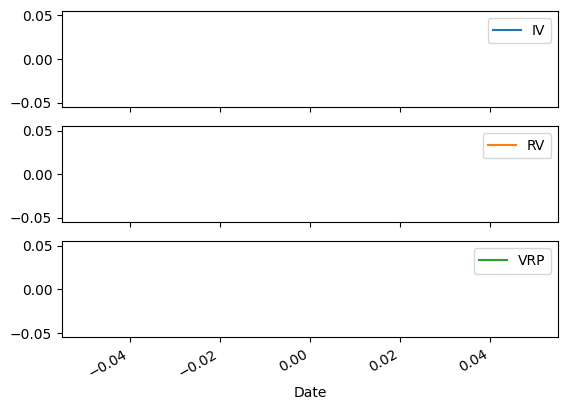

In [18]:
df[["IV", "RV", "VRP"]].plot(subplots=True)

In [19]:
df["RV_ann"] = df["RV"] * 252
df["IV_ann"] = df["IV"] * 252
df["VRP_ann"] = df["VRP"] * 252

In [20]:
df

,IV,RV,VRP,ret,rf,excess_ret,ret_fwd,RV_ann,IV_ann,VRP_ann
Date,,,,,,,,,,


### Cay Data

In [21]:
cay = pd.read_csv("data/cay_current.csv")

In [22]:
cay

,date,c,w,y,cay=c-0.218 a-0.801y+0.441
0,1952-03-31,9.155654,10.964372,8.979659,0.015105
1,1952-06-30,9.171140,10.981857,8.982086,0.024837
2,1952-09-30,9.171598,10.978478,8.996057,0.014840
3,1952-12-31,9.201695,10.972688,9.026059,0.022166
4,1953-03-31,9.209631,10.973457,9.036562,0.021521
...,...,...,...,...,...
266,2018-09-30,10.591508,12.647892,10.369712,-0.029345
267,2018-12-31,10.593748,12.605162,10.372724,-0.020207
268,2019-03-31,10.595604,12.650841,10.392760,-0.044354
269,2019-06-30,10.605677,12.662190,10.393868,-0.037642


In [23]:
cay = cay.rename(columns={"cay=c-0.218 a-0.801y+0.441": "cay"})

### Shiller Data

In [24]:
df_shiller = pd.read_excel("data/ie_data.xls", sheet_name="Data", engine="xlrd", skiprows=7)

In [25]:
df_shiller.tail(20)

,Date,P,D,E,CPI,Fraction,Rate GS10,Price,Dividend,Price.1,...,CAPE,Unnamed: 13,TR CAPE,Unnamed: 15,Yield,Returns,Returns.1,Real Return,Real Return.1,Returns.2
1845,2024.10,5792.319565,73.877418,203.570000,315.664,2024.791667,4.1,6017.483364,76.749242,4.022194e+06,...,36.587211,NaN,39.375226,NaN,0.015221,0.982514,40.006731,NaN,NaN,NaN
1846,2024.11,5929.916,74.354836,206.870000,315.493,2024.875000,4.36,6163.767567,77.287086,4.124278e+06,...,37.350196,NaN,40.176632,NaN,0.012564,1.001225,39.328482,NaN,NaN,NaN
1847,2024.12,6010.908571,74.832255,210.170000,315.605,2024.958333,4.39,6245.736917,77.755729,4.183460e+06,...,37.711192,NaN,40.544845,NaN,0.012630,0.984603,39.362679,NaN,NaN,NaN
1848,2025.01,5979.5155,75.269937,212.343333,317.671,2025.041667,4.63,6172.709881,77.701861,4.138883e+06,...,37.129220,NaN,39.899969,NaN,0.011804,1.018269,38.504542,NaN,NaN,NaN
1849,2025.02,6038.69,75.707619,214.516667,319.082,2025.125000,4.45,6206.230046,77.808084,4.165706e+06,...,37.187176,NaN,39.943400,NaN,0.013572,1.017426,39.034610,NaN,NaN,NaN
1850,2025.03,5683.983333,76.145301,216.690000,319.799,2025.208333,4.28,5828.584997,78.082453,3.916593e+06,...,34.784750,NaN,37.348615,NaN,0.016749,1.003567,39.625790,NaN,NaN,NaN
1851,2025.04,5369.495714,76.546867,218.636667,320.795,2025.291667,4.28,5489.001495,78.250527,3.692788e+06,...,32.621270,NaN,35.015341,NaN,0.018767,0.992343,39.643654,NaN,NaN,NaN
1852,2025.05,5810.919524,76.948434,220.583333,321.465,2025.375000,4.42,5927.869103,78.497085,3.992442e+06,...,35.076697,NaN,37.637336,NaN,0.014912,1.006896,39.258095,NaN,NaN,NaN
1853,2025.06,6029.9515,77.350000,222.530000,322.561,2025.458333,4.38,6130.408319,78.638623,4.133266e+06,...,36.111092,NaN,38.732625,NaN,0.014485,1.002847,39.394513,NaN,NaN,NaN
1854,2025.07,6296.498182,77.726667,226.770000,323.048,2025.541667,4.39,6391.745366,78.902439,4.313899e+06,...,37.474246,NaN,40.178756,NaN,0.013527,1.014158,39.447119,NaN,NaN,NaN


In [26]:
df_shiller["Date"] = pd.to_datetime(
    df_shiller["Date"].map(lambda x: f"{x:.2f}"),
    format="%Y.%m",
    errors="coerce"
)

In [27]:
p = pd.to_numeric(df_shiller["P"], errors="coerce")
e = pd.to_numeric(df_shiller["E"], errors="coerce")
d = pd.to_numeric(df_shiller["D"], errors="coerce")

df_shiller["log_PE"] = np.log(p / e)
df_shiller["log_PD"] = np.log(p / d)

In [43]:
df_shiller.head(20)

,Date,P,D,E,CPI,Fraction,Rate GS10,Price,Dividend,Price.1,...,TR CAPE,Unnamed: 15,Yield,Returns,Returns.1,Real Return,Real Return.1,Returns.2,log_PE,log_PD
0,1871-01-01,4.44,0.2600,0.4000,12.464061,1871.041667,5.32,116.818288,6.840711,116.818288,...,NaN,NaN,NaN,1.004177,1.000000,0.130609,0.092504,0.038106,2.406945,2.837728
1,1871-02-01,4.5,0.2600,0.4000,12.844641,1871.125000,5.323333,114.888874,6.638024,115.442042,...,NaN,NaN,NaN,1.004180,0.974424,0.130858,0.094635,0.036224,2.420368,2.851151
2,1871-03-01,4.61,0.2600,0.4000,13.034972,1871.208333,5.326667,115.978708,6.541098,117.084840,...,NaN,NaN,NaN,1.004183,0.964209,0.130951,0.096186,0.034765,2.444519,2.875302
3,1871-04-01,4.74,0.2600,0.4000,12.559226,1871.291667,5.33,123.766437,6.788876,125.517979,...,NaN,NaN,NaN,1.004185,1.004919,0.122056,0.090972,0.031084,2.472328,2.903111
4,1871-05-01,4.86,0.2600,0.4000,12.273812,1871.375000,5.333333,129.850689,6.946745,132.275423,...,NaN,NaN,NaN,1.004188,1.032591,0.122638,0.089488,0.033150,2.497329,2.928112
5,1871-06-01,4.82,0.2600,0.4000,12.083481,1871.458333,5.336667,130.810442,7.056165,133.852092,...,NaN,NaN,NaN,1.004191,1.053249,0.123093,0.087725,0.035368,2.489065,2.919848
6,1871-07-01,4.73,0.2600,0.4000,12.083481,1871.541667,5.34,128.367924,7.056165,131.954466,...,NaN,NaN,NaN,1.004194,1.057663,0.120022,0.086581,0.033441,2.470216,2.900999
7,1871-08-01,4.79,0.2600,0.4000,11.893231,1871.625000,5.343333,132.075750,7.169039,136.379998,...,NaN,NaN,NaN,1.004197,1.079088,0.111933,0.082669,0.029264,2.482821,2.913604
8,1871-09-01,4.84,0.2600,0.4000,12.178646,1871.708333,5.346667,130.326816,7.001027,135.176500,...,NaN,NaN,NaN,1.004199,1.058222,0.110028,0.081048,0.028980,2.493205,2.923988
9,1871-10-01,4.59,0.2600,0.4000,12.368896,1871.791667,5.35,121.694007,6.893342,126.818271,...,NaN,NaN,NaN,1.004202,1.046320,0.114765,0.081653,0.033113,2.440171,2.870954


### Merge

In [29]:
shiller_factors = df_shiller.copy()

if "Date" in shiller_factors.columns:
    shiller_factors = shiller_factors.set_index("Date")

shiller_factors = shiller_factors[["log_PE", "log_PD"]]
shiller_factors = shiller_factors[shiller_factors.index.notna()]
shiller_factors.index = shiller_factors.index.to_period("M").to_timestamp("M")

cay_series = cay[["date", "cay"]].copy()
cay_series["date"] = pd.to_datetime(cay_series["date"])
cay_series = cay_series.set_index("date").sort_index()

# Monthly Index erzeugen
cay_series = cay_series.resample("ME").ffill()

df = df.join(shiller_factors, how="left")
df = df.join(cay_series[["cay"]], how="left")


df[["log_PE", "log_PD", "cay"]].tail()

,log_PE,log_PD,cay
Date,,,


In [30]:
df.to_csv("data/data.csv")

### FRED DATA

In [31]:
start = "1985-01-01"  # früher starten wegen rolling mean!
end = df.index.max()

fred_series = {
    "BAA": "BAA",        # Corporate BAA yield
    "AAA": "AAA",        # Corporate AAA yield
    "GS10": "GS10",      # 10Y Treasury
}

data = {}

for name, code in fred_series.items():
    data[name] = web.DataReader(code, "fred", start, end)

fred = pd.concat(data.values(), axis=1)
fred.columns = fred_series.keys()

fred.head()

,BAA,AAA,GS10
DATE,,,
1985-01-01,13.26,12.08,11.38
1985-02-01,13.23,12.13,11.51
1985-03-01,13.69,12.56,11.86
1985-04-01,13.51,12.23,11.43
1985-05-01,13.15,11.72,10.85


In [32]:
# auf Monatsende resamplen
fred = fred.resample("ME").last()

# Index → Spalte
fred = fred.reset_index().rename(columns={"DATE": "Date"})

In [33]:
fred["Date"] = pd.to_datetime(fred["Date"])
df.index = pd.to_datetime(df.index)

df = df.join(fred.set_index("Date"), how="left")

In [34]:
df

,IV,RV,VRP,ret,rf,excess_ret,ret_fwd,RV_ann,IV_ann,VRP_ann,log_PE,log_PD,cay,BAA,AAA,GS10
Date,,,,,,,,,,,,,,,,


## Variable Calculation

### Default Spread DFSP

In [35]:
df["DFSP"] = df["BAA"] - df["AAA"]

### Term Spread TMSP

In [36]:
df["TMSP"] = df["GS10"] - df["rf"]

### Relative T-Bill Rate

In [37]:
df["RREL"] = df["rf"] - df["rf"].rolling(12).mean()

In [38]:
df["RREL"] = df["RREL"].bfill()

## Data Imputation

In [39]:
df.isna().sum()

IV            0
RV            0
VRP           0
ret           0
rf            0
excess_ret    0
ret_fwd       0
RV_ann        0
IV_ann        0
VRP_ann       0
log_PE        0
log_PD        0
cay           0
BAA           0
AAA           0
GS10          0
DFSP          0
TMSP          0
RREL          0
dtype: int64

In [40]:
df

,IV,RV,VRP,ret,rf,excess_ret,ret_fwd,RV_ann,IV_ann,VRP_ann,log_PE,log_PD,cay,BAA,AAA,GS10,DFSP,TMSP,RREL
Date,,,,,,,,,,,,,,,,,,,


<Axes: xlabel='Date'>

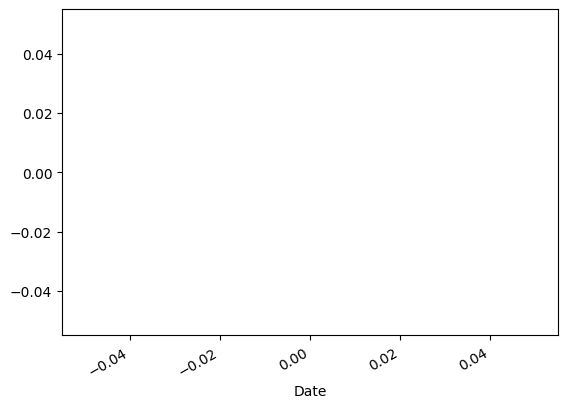

In [41]:
df['cay'].plot()

In [42]:
cay_series = df["cay"].astype(float)
exog_vars = ["log_PD", "log_PE", "excess_ret"]
exog = df[exog_vars].astype(float)

kalman_model = sm.tsa.UnobservedComponents(
    endog=cay_series,
    level="local level",
    exog=exog
)

kalman_res = kalman_model.fit(disp=False)
cay_fitted = kalman_res.predict()

df["cay_imputed"] = cay_series.fillna(cay_fitted)
df["cay"] = df["cay_imputed"]

print("# of NaN's after Imputation:", int(df["cay"].isna().sum()))
print("\nTail:")
print(df[["cay"]].tail(12))

ValueError: zero-size array to reduction operation maximum which has no identity

In [ ]:
df.to_csv("data/final.csv")